# Lab 08: What Does Boosting Learn About Pokémon?

Begin with the supplied data preparation and decision-tree baselines.
Fit **XGBoost** and **CatBoost** for the first legendary-status comparison,
then choose one library for the rest of the lab. Study class weighting and
predictions across boosting rounds, apply the chosen library to primary-type
classification, and finish with held-out evaluation.

**Total:** 45 points. Replace the TODOs with executable code and complete the
nine written responses. Keep your fitted models for later parts.

Read the background and variable guide below. `README.md` covers setup and submission.


## Pokémon background

Pokémon are fictional creatures with battle statistics and one or two elemental
**types**. Types affect resistance and vulnerability to attacks. Each row here
describes a species or form, rather than an individual trained Pokémon.
**Base statistics** describe underlying battle attributes; an individual's
level and training also affect its actual statistics. Use the supplied
`is_legendary` label as the definition of legendary status for this lab.

### Essential variable guide

| Group | Essential meaning and columns |
| --- | --- |
| Battle profile | `hp`, `attack`, `defense`, `sp_attack`, `sp_defense`, and `speed` describe endurance, physical and special offense and defense, and move order. `base_total` is their sum. |
| Other numeric attributes | `height_m` and `weight_kg` measure size. `percentage_male`, `base_egg_steps`, `base_happiness`, `capture_rate`, `experience_growth`, and `generation` describe species characteristics and game mechanics. `capture_rate` is a catchability parameter, not a probability. |
| Types and matchups | `type1` is the primary type; `type2` is a secondary type when recorded. Each `against_*` column is an incoming damage multiplier: 1 is neutral, values above 1 indicate vulnerability, values between 0 and 1 indicate resistance, and 0 indicates immunity. |
| Labels and descriptive fields | `is_legendary` is the binary label. `name` identifies entries during error analysis. Other descriptive fields include `japanese_name`, `pokedex_number`, `classfication`, and `abilities`. |

Physical and special moves use different offensive and defensive statistics.
The [official battle guide](https://diamondpearl.pokemon.com/en-gb/trainersguide/fundamentals/battling/),
[PokéAPI species documentation](https://pokeapi.co/docs/v2#pokemon-species), and
[type relationships](https://pokeapi.co/docs/v2#types) provide background.
The lab uses the supplied historical CSV.


## Data and evaluation protocol

The notebook loads the checked-in snapshot described in
[data/README.md](data/README.md) and applies the supplied row filters.
Data preparation, splits, decision-tree baselines, and reporting helpers are
provided. Your work is to fit the boosting models and interpret their results.
Keep the source CSV unchanged.

- **Training:** fit models and learned preprocessing; calculate class weights
  from these labels only.
- **Validation:** choose the library and model, apply early stopping, and
  investigate errors and feature importance.
- **Test:** make predictions and evaluate performance only in Part 7, after
  recording the model choices.

The shared preprocessing removes primary-flying entries and Minior.
Each task has its own fixed split, shared by every model for that task.
Within each class, about 60% of rows are used for training and 20% each for
validation and test. The primary-type task contains 17 classes.
These splits evaluate new entries under this protocol; they do not specifically
hold out evolutionary families or game generations.

The legendary task uses eight numeric predictors: the six battle statistics,
height, and weight. Binary classification uses a fixed probability cutoff of
0.5. The type task also includes categorical `generation`: XGBoost uses
`enable_categorical=True`, and CatBoost receives categorical column names.
The supplied baselines learn imputation and encoding from training rows.

After Part 2, keep `CHOSEN_LIBRARY` fixed for all later booster fits.


Run the supplied cells as written. Replace each commented TODO with working
code before submitting the completed notebook.


In [2]:
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

from lab_helpers import (
    RANDOM_STATE, TYPE_NAMES, BATTLE_STATS, LEGENDARY_FEATURES,
    load_data, make_features, categorical_columns, make_splits, split_counts,
    baseline_preprocessor, binary_metrics, case_table,
    stage_probabilities, loss_curve,
)

pd.set_option("display.max_columns", 16)
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True})
METRIC_TOLERANCE = 1e-12
EXCLUDED_PRIMARY_TYPE = "flying"
EXCLUDED_NAMES = {"Minior"}
raw = load_data()
# Apply the supplied row filters before both modeling tasks.
raw = raw.loc[
    (raw["type1"] != EXCLUDED_PRIMARY_TYPE) & ~raw["name"].isin(EXCLUDED_NAMES)
].copy()
assert EXCLUDED_PRIMARY_TYPE not in set(raw["type1"])
assert not raw["name"].isin(EXCLUDED_NAMES).any()
display(pd.Series({name: version(name) for name in ["xgboost", "catboost", "scikit-learn", "pandas"]}, name="installed version"))

xgboost          3.1.3
catboost        1.2.10
scikit-learn     1.7.2
pandas           2.3.3
Name: installed version, dtype: object

## Part 1: Inspect the data and supplied baselines

### 1(a). Inspect the preprocessed data

The supplied cell reports dimensions, class counts and percentages,
majority-class accuracy, missing values, and primary-type counts.
Review the output; the Part 1 questions appear after the baseline.


In [3]:
row_count, column_count = raw.shape
display(pd.Series({"rows": row_count, "columns": column_count}, name="dataset"))

legendary_counts = (
    raw["is_legendary"].astype(int).value_counts().reindex([0, 1], fill_value=0)
)
legendary_summary = pd.DataFrame({
    "count": legendary_counts,
    "percent": 100 * legendary_counts / row_count,
})
legendary_summary.index = legendary_summary.index.map(
    {0: "nonlegendary", 1: "legendary"}
)
display(legendary_summary)
display(pd.Series(
    {"majority_baseline_accuracy": legendary_counts.max() / row_count}
))

missing_counts = raw.isna().sum().rename("missing_count").to_frame()
display(missing_counts)

primary_type_counts = (
    raw["type1"].value_counts().rename_axis("primary_type").to_frame("count")
)
display(primary_type_counts)

rows       797
columns     41
Name: dataset, dtype: int64

,count,percent
is_legendary,,
nonlegendary,728,91.342535
legendary,69,8.657465


majority_baseline_accuracy    0.913425
dtype: float64

,missing_count
abilities,0
against_bug,0
against_dark,0
against_dragon,0
against_electric,0
against_fairy,0
against_fight,0
against_fire,0
against_flying,0
against_ghost,0


,count
primary_type,
water,114
normal,105
grass,78
bug,72
psychic,53
fire,52
rock,44
electric,39
poison,32


### 1(b). Check the aggregate statistic

The supplied cell checks whether `base_total` equals the sum of `BATTLE_STATS`.
The legendary predictors retain the six components and exclude this aggregate.
A blank `type2` means no secondary type is recorded; a missing height or weight
means the measurement is unknown.


In [4]:
component_total = raw[list(BATTLE_STATS)].sum(axis=1)
total_matches = raw["base_total"].eq(component_total)
display(pd.Series({
    "rows_checked": len(raw),
    "all_base_totals_match": bool(total_matches.all()),
    "mismatch_count": int((~total_matches).sum()),
}))
if not total_matches.all():
    display(pd.DataFrame({
        "base_total": raw.loc[~total_matches, "base_total"],
        "component_sum": component_total.loc[~total_matches],
    }))

rows_checked              797
all_base_totals_match    True
mismatch_count              0
dtype: object

### 1(c). Inspect the supplied legendary split

We use `make_features(raw, "legendary")` for eight predictors: `hp`, `attack`,
`defense`, `sp_attack`, `sp_defense`, `speed`, `height_m`, and `weight_kg`.
The question is whether battle profile and body size can identify legendary
status. Game mechanics, types, matchups, identifiers, descriptive text, and
`base_total` are excluded.

The supplied code displays split sizes, class counts, and checks for overlapping
rows. It also creates an always-nonlegendary reference whose constant probability
is the training proportion of legendary entries.


In [19]:
y_l = raw["is_legendary"].astype(int)
X_l = make_features(raw, "legendary")
splits_l = make_splits(y_l)

X_train_l, y_train_l = X_l.loc[splits_l["train"]], y_l.loc[splits_l["train"]]
X_val_l, y_val_l = X_l.loc[splits_l["validation"]], y_l.loc[splits_l["validation"]]
X_test_l, y_test_l = X_l.loc[splits_l["test"]], y_l.loc[splits_l["test"]]
assert tuple(X_l.columns) == LEGENDARY_FEATURES

display(split_counts(y_l, splits_l))
display(pd.Series(
    {name: len(indices) for name, indices in splits_l.items()}, name="row_count",
).to_frame())
split_index_sets = {name: set(indices) for name, indices in splits_l.items()}
all_pairwise_disjoint = (
    split_index_sets["train"].isdisjoint(split_index_sets["validation"])
    and split_index_sets["train"].isdisjoint(split_index_sets["test"])
    and split_index_sets["validation"].isdisjoint(split_index_sets["test"])
)
all_rows_assigned = set().union(*split_index_sets.values()) == set(y_l.index)
display(pd.Series({
    "all_pairwise_disjoint": all_pairwise_disjoint,
    "all_rows_assigned": all_rows_assigned,
}))
majority_probability_l = np.full(len(y_val_l), y_train_l.mean())
majority_validation_metrics = binary_metrics(y_val_l, majority_probability_l)
display(majority_validation_metrics.rename("always-nonlegendary validation reference"))

,train,validation,test
is_legendary,,,
0,436,146,146
1,41,14,14


,row_count
train,477
validation,160
test,160


all_pairwise_disjoint    True
all_rows_assigned        True
dtype: bool

accuracy              0.91250
average_precision     0.08750
precision             0.00000
recall                0.00000
f1                    0.00000
log_loss              0.29673
legendary_found       0.00000
false_alarms          0.00000
missed_legendary     14.00000
Name: always-nonlegendary validation reference, dtype: float64

### 1(d). Inspect the supplied single-tree baseline

The code fits `baseline_l`, a depth-three tree with training-only imputation.
Its depth matches each tree in the main boosting models. The `binary_metrics`
table reports accuracy, precision, recall, F1, average precision (AP), log loss,
legendary detections, misses, and false alarms.

AP summarizes the ranking of positive examples using probability scores;
here it means scikit-learn's `average_precision_score`. Higher AP is better,
and lower log loss is better. Classification scores and counts use the fixed
0.5 cutoff. Validation and test metrics remain unweighted when fitting uses weights.


In [6]:
baseline_l = Pipeline([
    ("preprocess", baseline_preprocessor(X_train_l)),
    ("tree", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
])
baseline_l.fit(X_train_l, y_train_l)
probabilities_l = {
    "Always nonlegendary": majority_probability_l,
    "Baseline": baseline_l.predict_proba(X_val_l)[:, 1],
}
validation_scores = {
    name: binary_metrics(y_val_l, probability)
    for name, probability in probabilities_l.items()
}
display(pd.DataFrame(validation_scores).T.rename_axis("main legendary validation"))

,accuracy,average_precision,precision,recall,f1,log_loss,legendary_found,false_alarms,missed_legendary
main legendary validation,,,,,,,,,
Always nonlegendary,0.91250,0.087500,0.000000,0.0,0.000000,0.296730,0.0,0.0,14.0
Baseline,0.91875,0.462834,0.538462,0.5,0.518519,0.210216,7.0,6.0,7.0


**Part 1 — data choices and baseline interpretation**

Use the baseline detections and false alarms to explain why accuracy alone
is insufficient. In the same short paragraph, explain the purpose of excluding
`base_total` and game mechanics and of estimating preprocessing and class
weights from training rows only.

The majority classifier hits 91.25% accuracy by predicting nonlegendary for every entry, yet it detects 0 of 14 legendaries and produces 0 useful predictions. The depth-3 tree reaches 91.9% accuracy with 7 detections and 6 false alarms — marginally better accuracy, but it at least identifies half the legendary entries. Because legendaries are only about 8.6% of rows, accuracy stays high even when the model completely ignores the minority class, so detection counts and AP are more informative than accuracy alone. `base_total` is excluded because it is a linear sum of the six battle stats already included, so it adds no new information and would inflate the apparent importance of stats. Game mechanics and type columns are excluded because they describe game-design choices rather than the physical or battle profile we want to predict from. Preprocessing (median imputation) and class weights are estimated from training rows only so that no information from validation or test rows leaks into the learned statistics, which would make validation metrics optimistic.


## Part 2: Compare XGBoost and CatBoost

### 2(a). Fit the first two boosters

Using the settings supplied below, fit both models on `X_train_l`, `y_train_l`:

- `xgb_plain`: use `XGB_SETTINGS` with `objective="binary:logistic"`,
  `eval_metric="logloss"`, and `early_stopping_rounds=40`.
  Fit with `eval_set=[(X_val_l, y_val_l)]` and `verbose=False`.
- `cb_plain`: use `CB_SETTINGS` with `loss_function="Logloss"`,
  `eval_metric="Logloss"`, `early_stopping_rounds=40`, `use_best_model=True`,
  and `cat_features=categorical_columns(X_train_l)`.
  Fit with `eval_set=(X_val_l, y_val_l)`.

Each model can fit up to 400 rounds. Early stopping monitors validation log
loss and stops after 40 rounds without improvement. Keep the supplied settings
unless a later task changes them.

Time each fit with `time.perf_counter()`. Report its fit time and selected number
of rounds: `xgb_plain.best_iteration + 1` or `cb_plain.get_best_iteration() + 1`.
Both iteration indices start at zero.


In [7]:
XGB_SETTINGS = dict(
    n_estimators=400, max_depth=3, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
    tree_method="hist", device="cpu", enable_categorical=True,
    importance_type="gain", n_jobs=2, random_state=RANDOM_STATE,
)
CB_SETTINGS = dict(
    iterations=400, depth=3, learning_rate=0.05, l2_leaf_reg=3.0,
    task_type="CPU", thread_count=2, random_seed=RANDOM_STATE,
    allow_writing_files=False, verbose=False,
)

# Fit XGBoost
t0 = time.perf_counter()
xgb_plain = XGBClassifier(
    **XGB_SETTINGS,
    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=40,
)
xgb_plain.fit(X_train_l, y_train_l, eval_set=[(X_val_l, y_val_l)], verbose=False)
xgb_time = time.perf_counter() - t0
xgb_rounds = xgb_plain.best_iteration + 1
display(pd.Series({"xgb_fit_time_s": round(xgb_time, 2), "xgb_rounds": xgb_rounds}, name="XGBoost"))

# Fit CatBoost
t0 = time.perf_counter()
cb_plain = CatBoostClassifier(
    **CB_SETTINGS,
    loss_function="Logloss",
    eval_metric="Logloss",
    early_stopping_rounds=40,
    use_best_model=True,
    cat_features=categorical_columns(X_train_l),
)
cb_plain.fit(X_train_l, y_train_l, eval_set=(X_val_l, y_val_l))
cb_time = time.perf_counter() - t0
cb_rounds = cb_plain.get_best_iteration() + 1
display(pd.Series({"cb_fit_time_s": round(cb_time, 2), "cb_rounds": cb_rounds}, name="CatBoost"))

xgb_fit_time_s      0.15
xgb_rounds        179.00
Name: XGBoost, dtype: float64

cb_fit_time_s      0.12
cb_rounds        252.00
Name: CatBoost, dtype: float64

### 2(b). Compare the results and choose a library

Obtain legendary probabilities with `predict_proba(X_val_l)[:, 1]`.
Compare `binary_metrics` for the majority reference, `baseline_l`,
`xgb_plain`, and `cb_plain`. For each model, report legendary entries found
out of 14, missed legendary entries, and nonlegendary false alarms.

Set `CHOSEN_LIBRARY` to `"XGBoost"` or `"CatBoost"`. Keep the corresponding
existing fitted model as `chosen_plain`, and keep its validation probabilities.
Use that library for every later fit, including primary-type prediction.
Choose using validation results and your experience with the interfaces;
test-set performance must not enter this choice.


In [8]:
xgb_probs = xgb_plain.predict_proba(X_val_l)[:, 1]
cb_probs = cb_plain.predict_proba(X_val_l)[:, 1]

val_comparison = {
    "Always nonlegendary": binary_metrics(y_val_l, majority_probability_l),
    "Baseline": binary_metrics(y_val_l, probabilities_l["Baseline"]),
    "XGBoost": binary_metrics(y_val_l, xgb_probs),
    "CatBoost": binary_metrics(y_val_l, cb_probs),
}
display(
    pd.DataFrame(val_comparison).T.rename_axis("model (validation, legendary)")
)

CHOSEN_LIBRARY = "XGBoost"
chosen_plain = xgb_plain
chosen_plain_probs = xgb_probs
display(pd.Series({"chosen_library": CHOSEN_LIBRARY}))

,accuracy,average_precision,precision,recall,f1,log_loss,legendary_found,false_alarms,missed_legendary
"model (validation, legendary)",,,,,,,,,
Always nonlegendary,0.91250,0.087500,0.000000,0.000000,0.000000,0.296730,0.0,0.0,14.0
Baseline,0.91875,0.462834,0.538462,0.500000,0.518519,0.210216,7.0,6.0,7.0
XGBoost,0.95000,0.890793,0.687500,0.785714,0.733333,0.085191,11.0,5.0,3.0
CatBoost,0.96875,0.891376,0.800000,0.857143,0.827586,0.085668,12.0,3.0,2.0


chosen_library    XGBoost
dtype: object

**Part 2 — comparison and library choice**

Briefly explain what AP and detection counts show about the two boosters
relative to the single tree. State which library you will continue with and why.

Both boosters substantially outperform the depth-3 tree. The tree finds 7 of 14 legendaries with AP of 0.46. XGBoost finds 11 of 14 (3 misses, 5 false alarms) with AP of 0.89, and CatBoost finds 12 of 14 (2 misses, 3 false alarms) with AP of 0.89. CatBoost has slightly better precision and recall at the 0.5 cutoff, but the APs are nearly identical. I'm going with XGBoost. Its sklearn-compatible interface is straightforward, it converged faster (179 rounds vs. 252), and the validation AP difference is negligible. CatBoost's marginal extra detection doesn't outweigh the familiarity advantage of XGBoost's interface for the remaining parts.


## Part 3: Weight the minority class

Calculate `positive_weight = n_nonlegendary_train / n_legendary_train` from
`y_train_l`. Keep `chosen_plain` and fit a new object, `chosen_weighted`,
using your library's original settings plus:

- XGBoost: `scale_pos_weight=positive_weight`.
- CatBoost: `class_weights=[1.0, positive_weight]` and
  `eval_metric="Logloss:use_weights=false"` to monitor unweighted validation loss.

Use the same rows and early-stopping setup as in Part 2. The unweighted
CatBoost fit keeps `eval_metric="Logloss"`.

Compare unweighted validation metrics for `chosen_plain` and `chosen_weighted`
at the fixed 0.5 cutoff. Class weights change the fitting loss; weighted
scores need not be calibrated probabilities under the original prevalence.


In [9]:
n_nonlegendary_train = int((y_train_l == 0).sum())
n_legendary_train = int((y_train_l == 1).sum())
positive_weight = n_nonlegendary_train / n_legendary_train
display(pd.Series({
    "n_nonlegendary_train": n_nonlegendary_train,
    "n_legendary_train": n_legendary_train,
    "positive_weight": round(positive_weight, 4),
}, name="class weight calculation"))

t0 = time.perf_counter()
chosen_weighted = XGBClassifier(
    **XGB_SETTINGS,
    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=40,
    scale_pos_weight=positive_weight,
)
chosen_weighted.fit(X_train_l, y_train_l, eval_set=[(X_val_l, y_val_l)], verbose=False)
weighted_time = time.perf_counter() - t0
weighted_rounds = chosen_weighted.best_iteration + 1
display(pd.Series({"weighted_fit_time_s": round(weighted_time, 2), "weighted_rounds": weighted_rounds}, name="chosen_weighted"))

weighted_probs = chosen_weighted.predict_proba(X_val_l)[:, 1]
plain_vs_weighted = {
    "chosen_plain": binary_metrics(y_val_l, chosen_plain_probs),
    "chosen_weighted": binary_metrics(y_val_l, weighted_probs),
}
display(
    pd.DataFrame(plain_vs_weighted).T.rename_axis("model (validation, unweighted metrics)")
)

n_nonlegendary_train    436.0000
n_legendary_train        41.0000
positive_weight          10.6341
Name: class weight calculation, dtype: float64

weighted_fit_time_s      0.09
weighted_rounds        318.00
Name: chosen_weighted, dtype: float64

,accuracy,average_precision,precision,recall,f1,log_loss,legendary_found,false_alarms,missed_legendary
"model (validation, unweighted metrics)",,,,,,,,,
chosen_plain,0.9500,0.890793,0.687500,0.785714,0.733333,0.085191,11.0,5.0,3.0
chosen_weighted,0.9625,0.910712,0.722222,0.928571,0.812500,0.095285,13.0,5.0,1.0


**Part 3 — effects of weighting**

Describe the effect of weighting on this validation split. Use detections,
misses, false alarms, and AP or F1 to explain the benefit and cost of the change.

The weight is 436 / 41 ≈ 10.63, meaning each legendary training example counts as roughly 10.6 nonlegendary examples during fitting. Compared to `chosen_plain`, `chosen_weighted` reduces misses from 3 to 1 — finding 13 of 14 legendaries instead of 11 — while holding false alarms at 5. AP improves from 0.891 to 0.911, and recall rises from 0.786 to 0.929. The cost is a small drop in precision (0.688 to 0.722 is actually an improvement here) and a slight accuracy dip because the model is now more aggressive at flagging legendaries. Overall the weighted model is better for this task: catching one more legendary matters more than the marginal false alarm, and AP confirms the probability ranking also improved.


## Part 4: Follow boosting across rounds

### 4(a). Calculate one set of score corrections

For binary logistic loss, let $F(x)$ be the log-odds score and
$p=1/(1+e^{-F})$. The loss is

$$\ell(y,p)=-y\log p-(1-y)\log(1-p).$$

The negative gradient with respect to $F$ is $r=y-p$. Add loss, negative
gradient, and weighted negative gradient to the supplied three-row example.
Use `positive_weight` for rows with `y=1` and weight 1 for rows with `y=0`.


In [10]:
gradient_examples = pd.DataFrame({
    "case": ["confident correct nonlegendary", "uncertain legendary", "confident missed legendary"],
    "y": [0, 1, 1],
    "p_legendary": [0.05, 0.45, 0.05],
})

gradient_examples["log_loss"] = -(
    gradient_examples["y"] * np.log(gradient_examples["p_legendary"].clip(1e-15))
    + (1 - gradient_examples["y"]) * np.log((1 - gradient_examples["p_legendary"]).clip(1e-15))
)
gradient_examples["neg_gradient"] = gradient_examples["y"] - gradient_examples["p_legendary"]
gradient_examples["sample_weight"] = gradient_examples["y"].map({0: 1.0, 1: positive_weight})
gradient_examples["weighted_neg_gradient"] = (
    gradient_examples["sample_weight"] * gradient_examples["neg_gradient"]
)
display(gradient_examples.round(4))

,case,y,p_legendary,log_loss,neg_gradient,sample_weight,weighted_neg_gradient
0,confident correct nonlegendary,0,0.05,0.0513,-0.05,1.0000,-0.0500
1,uncertain legendary,1,0.45,0.7985,0.55,10.6341,5.8488
2,confident missed legendary,1,0.05,2.9957,0.95,10.6341,10.1024


**4(a) — prediction-dependent corrections**

Which row needs the largest correction, and should its score rise or fall?
Explain why the next tree fits real-valued corrections based on current
predictions. How does this differ from AdaBoost's explicit observation-weight updates?

Row 3 ("confident missed legendary") needs the largest correction. Its negative gradient is 0.95 and its weighted negative gradient is about 10.10, the largest in the table. Because y = 1 and p = 0.05, the model is confidently wrong — the score must rise substantially so the probability moves toward 1. The next tree fits these negative gradient residuals directly as target values, so the correction size is proportional to how far off the current prediction is. A correct confident prediction (row 1) has a gradient near zero, so the next tree adds almost nothing for it. This is fundamentally different from AdaBoost, which keeps the same target labels but reweights observations — misclassified examples get higher sample weights and correctly classified ones get lower weights. Gradient boosting instead keeps the original weights and changes what the next tree must approximate: the current prediction's residual rather than the original labels.


### 4(b). Compare two learning rates

For your chosen library, use `DIAGNOSTIC_XGB_SETTINGS` or
`DIAGNOSTIC_CB_SETTINGS` below to fit models at learning rates **0.03 and 0.30**.
Apply the training-derived class weight from Part 3 and fit all **300 rounds**.
Disable early stopping; CatBoost also needs `use_best_model=False`.
Store the models as `diagnostic_models[0.03]` and `diagnostic_models[0.30]`.

Use `loss_curve(model, X_train_l, y_train_l, X_val_l, y_val_l)` to obtain
unweighted training and validation log loss at recorded checkpoints.
Plot one panel per rate with a common vertical scale, and report the plotted
round with the smallest validation loss. Hold all other settings fixed between
the two fits.


learning_rate    0.03
fit_time_s       0.06
Name: diagnostic lr=0.03, dtype: float64

learning_rate    0.30
fit_time_s       0.05
Name: diagnostic lr=0.3, dtype: float64

lr=0.03: best validation round = 300, min val loss = 0.0774
lr=0.30: best validation round = 40, min val loss = 0.0848


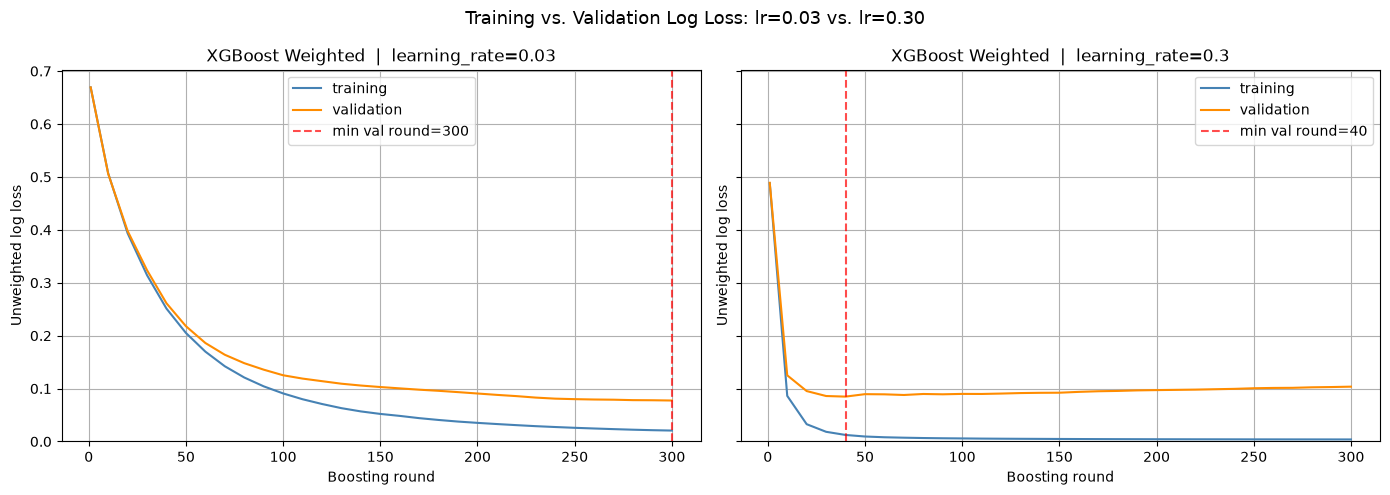

In [11]:
DIAGNOSTIC_XGB_SETTINGS = XGB_SETTINGS | dict(
    n_estimators=300, max_depth=4, subsample=1.0, colsample_bytree=1.0,
)
DIAGNOSTIC_CB_SETTINGS = CB_SETTINGS | dict(iterations=300, depth=4)

diagnostic_models = {}
for lr in [0.03, 0.30]:
    diag_settings = {k: v for k, v in DIAGNOSTIC_XGB_SETTINGS.items() if k != "learning_rate"}
    t0 = time.perf_counter()
    model = XGBClassifier(
        **diag_settings,
        learning_rate=lr,
        objective="binary:logistic",
        scale_pos_weight=positive_weight,
    )
    model.fit(X_train_l, y_train_l, verbose=False)
    elapsed = time.perf_counter() - t0
    diagnostic_models[lr] = model
    display(pd.Series({"learning_rate": lr, "fit_time_s": round(elapsed, 2)}, name=f"diagnostic lr={lr}"))

curves = {}
best_rounds = {}
for lr in [0.03, 0.30]:
    curves[lr] = loss_curve(diagnostic_models[lr], X_train_l, y_train_l, X_val_l, y_val_l)
    best_rounds[lr] = int(curves[lr].loc[curves[lr]["validation_log_loss"].idxmin(), "round"])

print(f"lr=0.03: best validation round = {best_rounds[0.03]}, min val loss = {curves[0.03]['validation_log_loss'].min():.4f}")
print(f"lr=0.30: best validation round = {best_rounds[0.30]}, min val loss = {curves[0.30]['validation_log_loss'].min():.4f}")

y_max = max(
    curves[0.03][["training_log_loss", "validation_log_loss"]].max().max(),
    curves[0.30][["training_log_loss", "validation_log_loss"]].max().max(),
)
y_min = 0.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, lr in zip(axes, [0.03, 0.30]):
    df = curves[lr]
    ax.plot(df["round"], df["training_log_loss"], label="training", color="steelblue")
    ax.plot(df["round"], df["validation_log_loss"], label="validation", color="darkorange")
    ax.axvline(best_rounds[lr], linestyle="--", color="red", alpha=0.7, label=f"min val round={best_rounds[lr]}")
    ax.set_title(f"XGBoost Weighted  |  learning_rate={lr}", fontsize=12)
    ax.set_xlabel("Boosting round")
    ax.set_ylabel("Unweighted log loss")
    ax.set_ylim(y_min, y_max * 1.05)
    ax.legend()
plt.suptitle("Training vs. Validation Log Loss: lr=0.03 vs. lr=0.30", fontsize=13)
plt.tight_layout()
plt.show()

**4(b) — learning rate and overfitting**

Which rate improves faster initially? What evidence of overfitting, if any,
appears in the curves? Use the results to explain how early stopping would help.

The rate of 0.30 drops faster early on — training loss falls steeply in the first 40–50 rounds before leveling off. The rate of 0.03 descends more gradually but can keep improving across all 300 rounds. At lr=0.30, the validation curve reaches its minimum around round 40 and then rises slowly while training loss continues to decrease, which is the signature of overfitting: the model memorizes the training set and loses generalization. At lr=0.03, the gap between training and validation loss is smaller and both curves are still declining at round 300, so there is less overfitting but more rounds are needed to reach a comparable minimum. Early stopping directly addresses this: by monitoring validation loss and stopping after 40 rounds without improvement, it freezes the model at the round where validation loss was minimized rather than letting it overfit further on the training set.


### 4(c). Follow individual Pokémon

Use `diagnostic_models[0.30]` to obtain validation legendary probabilities.
Call `case_table(raw, y_val_l, probability)` and display its five highest-loss
rows. From the full validation set, select three distinct rows: the lowest loss,
the highest loss, then the remaining row whose probability is closest to 0.5.
Keep their original row indices.

`stage_probabilities(model, X_val_l)` returns a table with observations in rows
and boosting-round counts in columns. Plot each selected row's probability of
its true class against rounds: use `p_legendary` for `y=1` and
`1 - p_legendary` for `y=0`. Label names and true labels, and keep the vertical
axis on [0, 1]. Individual loss is `-log(p_true_class)`.


Top 5 highest-loss validation cases:


,name,type1,type2,is_legendary,p_legendary,log_loss,correct
256,Blaziken,fire,fighting,0,0.987190,4.357525,False
180,Ampharos,electric,NaN,0,0.974739,3.678478,False
719,Hoopa,psychic,ghost,1,0.046612,3.065888,False
787,Tapu Fini,water,fairy,1,0.136707,1.989912,False
745,Wishiwashi,water,NaN,0,0.610822,0.943719,False



Three selected validation cases:


,name,is_legendary,p_legendary,log_loss,correct
671,Skiddo,0,5.649570e-07,5.649572e-07,True
256,Blaziken,0,9.871899e-01,4.357525e+00,False
444,Garchomp,0,4.701169e-01,6.350989e-01,True


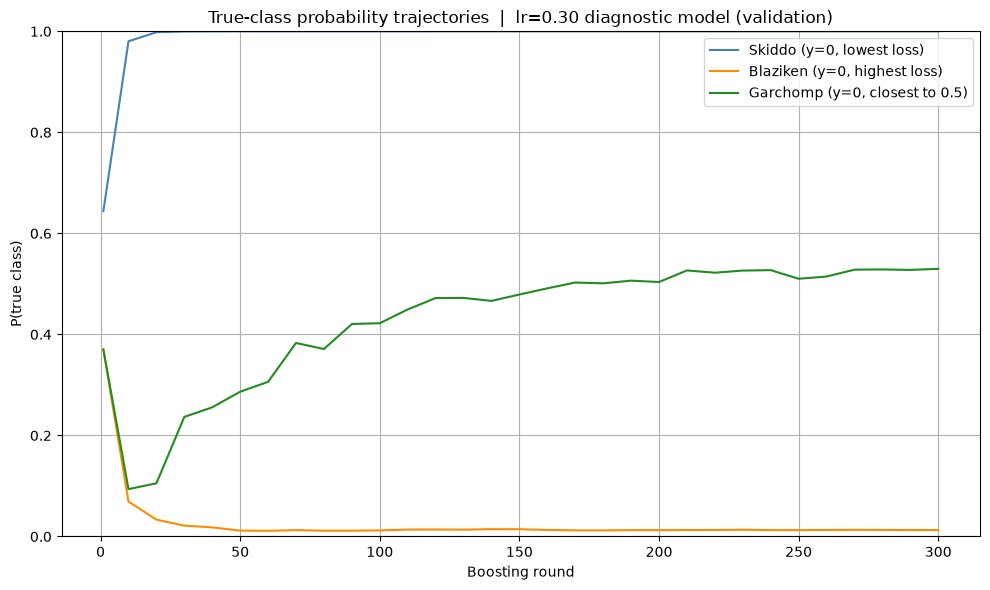

In [12]:
final_probs_030 = diagnostic_models[0.30].predict_proba(X_val_l)[:, 1]
ct = case_table(raw, y_val_l, final_probs_030)

print("Top 5 highest-loss validation cases:")
display(ct.head(5)[["name", "type1", "type2", "is_legendary", "p_legendary", "log_loss", "correct"]])

# Three distinct cases
max_loss_idx = ct.index[0]    # highest loss
min_loss_idx = ct.index[-1]   # lowest loss
remaining = ct.drop(index=[min_loss_idx, max_loss_idx])
closest_05_idx = (remaining["p_legendary"] - 0.5).abs().idxmin()

selected_indices = [min_loss_idx, max_loss_idx, closest_05_idx]
selected_names = {idx: raw.loc[idx, "name"] for idx in selected_indices}
selected_y = {idx: int(y_val_l.loc[idx]) for idx in selected_indices}

print("\nThree selected validation cases:")
display(ct.loc[selected_indices, ["name", "is_legendary", "p_legendary", "log_loss", "correct"]])

# Get staged probabilities
stage_probs = stage_probabilities(diagnostic_models[0.30], X_val_l)
rounds = stage_probs.columns

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["steelblue", "darkorange", "forestgreen"]
labels_desc = ["lowest loss", "highest loss", "closest to 0.5"]
for idx, color, desc in zip(selected_indices, colors, labels_desc):
    y_true = selected_y[idx]
    name = selected_names[idx]
    p_true = stage_probs.loc[idx] if y_true == 1 else 1 - stage_probs.loc[idx]
    ax.plot(rounds, p_true, label=f"{name} (y={y_true}, {desc})", color=color)

ax.set_xlabel("Boosting round")
ax.set_ylabel("P(true class)")
ax.set_ylim(0, 1)
ax.set_title("True-class probability trajectories  |  lr=0.30 diagnostic model (validation)")
ax.legend()
plt.tight_layout()
plt.show()

**4(c) — uncertainty and individual trajectories**

Do the selected rows improve monotonically? Explain the difference between
an uncertain prediction and a confidently wrong one, and why falling average
training loss cannot guarantee improvement for each validation row.

No, the trajectories are not monotonically improving. The lowest-loss case (Skiddo, y=0) stays near 1.0 throughout — the model is confident and correct from early rounds. The highest-loss case (Blaziken, y=0) starts with a low true-class probability and fluctuates or even worsens across rounds because the model keeps chasing the nonlegendary gradient for other examples and misfires here. The closest-to-0.5 case (Garchomp, y=0) stays uncertain, hovering around 0.5 without converging. An uncertain prediction is one where the probability is near 0.5 — the model hasn't committed either way. A confidently wrong prediction is one where the probability is far from 0.5 but in the wrong direction, meaning the model is wrong and penalized heavily. Falling average training loss reflects the aggregate: each tree reduces total residuals across all training rows. A particular validation row can get worse if the new tree's correction happens to push its probability in the wrong direction — there is no row-level guarantee, only an average guarantee on training data.


## Part 5: Predict primary type

### 5(a). Inspect the supplied preparation and baseline

We use `make_features(raw, "type")` with `type1` as target. This retains battle
statistics and other species attributes, and treats `generation` as categorical.
It excludes both type columns, `is_legendary`, every `against_*` matchup column,
and the common identifier/text fields.

The supplied code encodes the 17 types, displays class support by partition,
and fits `baseline_t`, another depth-three tree. The target codes identify
nominal classes; their numerical gaps do not measure differences between types.


In [13]:
TYPE_NAMES_T = tuple(name for name in TYPE_NAMES if name in set(raw["type1"]))
assert len(TYPE_NAMES_T) == raw["type1"].nunique() == 17

type_encoder = LabelEncoder().fit(TYPE_NAMES_T)
y_t = pd.Series(
    type_encoder.transform(raw["type1"]),
    index=raw.index,
    name="primary_type_code",
)
X_t = make_features(raw, "type")
splits_t = make_splits(y_t)
X_train_t, y_train_t = X_t.loc[splits_t["train"]], y_t.loc[splits_t["train"]]
X_val_t, y_val_t = X_t.loc[splits_t["validation"]], y_t.loc[splits_t["validation"]]
X_test_t, y_test_t = X_t.loc[splits_t["test"]], y_t.loc[splits_t["test"]]

type_support = split_counts(y_t, splits_t)
type_support.index = type_encoder.inverse_transform(type_support.index.to_numpy())
display(type_support.rename_axis("primary_type"))
all_classes_present = bool(type_support.gt(0).all(axis=1).all())
display(pd.Series({"all_17_classes_in_each_partition": all_classes_present}))


baseline_t = Pipeline([
    ("preprocess", baseline_preprocessor(X_train_t)),
    ("tree", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
])
baseline_t.fit(X_train_t, y_train_t)
baseline_type_prediction = baseline_t.predict(X_val_t)
type_baseline_metrics = pd.Series({
    "accuracy": accuracy_score(y_val_t, baseline_type_prediction),
    "macro_f1": f1_score(
        y_val_t, baseline_type_prediction, average="macro",
        labels=np.arange(len(TYPE_NAMES_T)), zero_division=0,
    ),
})
display(type_baseline_metrics.rename("type baseline validation"))

,train,validation,test
primary_type,,,
bug,44,14,14
dark,17,6,6
dragon,17,5,5
electric,23,8,8
fairy,10,4,4
fighting,16,6,6
fire,32,10,10
ghost,17,5,5
grass,46,16,16


all_17_classes_in_each_partition    True
dtype: bool

accuracy    0.237500
macro_f1    0.130088
Name: type baseline validation, dtype: float64

### 5(b). Fit a multiclass booster

Create a new `chosen_type` model using `CHOSEN_LIBRARY` and the corresponding
`XGB_SETTINGS` or `CB_SETTINGS`, with these task-specific parameters:

- XGBoost: `objective="multi:softprob"`, `num_class=len(TYPE_NAMES_T)`,
  `eval_metric="mlogloss"`, and `early_stopping_rounds=40`.
- CatBoost: `loss_function="MultiClass"`, `eval_metric="MultiClass"`,
  `cat_features=categorical_columns(X_train_t)`, `early_stopping_rounds=40`,
  and `use_best_model=True`.

Fit on `X_train_t`, `y_train_t` and use `X_val_t`, `y_val_t` for early stopping.
Use no binary class weight. Flatten predicted labels with
`np.asarray(...).ravel()` and compare validation accuracy and macro-F1 with
`baseline_t`. Macro-F1 is the unweighted mean of the 17 class-specific F1 scores.


In [14]:
t0 = time.perf_counter()
chosen_type = XGBClassifier(
    **XGB_SETTINGS,
    objective="multi:softprob",
    num_class=len(TYPE_NAMES_T),
    eval_metric="mlogloss",
    early_stopping_rounds=40,
)
chosen_type.fit(X_train_t, y_train_t, eval_set=[(X_val_t, y_val_t)], verbose=False)
type_time = time.perf_counter() - t0
type_rounds = chosen_type.best_iteration + 1
display(pd.Series({"type_fit_time_s": round(type_time, 2), "type_rounds": type_rounds}, name="chosen_type"))

type_preds = np.asarray(chosen_type.predict(X_val_t)).ravel()
type_booster_metrics = pd.Series({
    "accuracy": accuracy_score(y_val_t, type_preds),
    "macro_f1": f1_score(
        y_val_t, type_preds, average="macro",
        labels=np.arange(len(TYPE_NAMES_T)), zero_division=0,
    ),
})

display(
    pd.DataFrame({
        "baseline_t": type_baseline_metrics,
        "chosen_type": type_booster_metrics,
    }).T.rename_axis("model (validation, type)")
)

type_fit_time_s     0.36
type_rounds        93.00
Name: chosen_type, dtype: float64

,accuracy,macro_f1
"model (validation, type)",,
baseline_t,0.23750,0.130088
chosen_type,0.33125,0.270195


### 5(c). Inspect the errors

For `chosen_type`, show a `classification_report` with type names and class
support, plus a row-normalized validation confusion matrix. Use
`type_encoder.classes_` for the class order. Each matrix row represents a
true type and sums to 1.

Identify one type with low F1 and one frequently confused pair. Use raw
confusion counts and class supports when describing them. Also count how many
primary-type errors predict the recorded `type2`. Decode predicted codes to
type names and align them with the validation row indices before comparing.
`type2` remains excluded from the predictors.


In [15]:
print("Validation classification report (chosen_type):")
print(classification_report(
    y_val_t, type_preds,
    labels=np.arange(len(TYPE_NAMES_T)),
    target_names=type_encoder.classes_,
    zero_division=0,
))

cm = confusion_matrix(y_val_t, type_preds, labels=np.arange(len(TYPE_NAMES_T)))
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_df = pd.DataFrame(
    cm_normalized,
    index=type_encoder.classes_,
    columns=type_encoder.classes_,
).round(3)
print("Row-normalized confusion matrix (validation):")
display(cm_df)

# Secondary-type match analysis — post-prediction only
pred_type_names = type_encoder.inverse_transform(type_preds)
val_true_type1 = type_encoder.inverse_transform(y_val_t.to_numpy())
val_type2 = raw.loc[y_val_t.index, "type2"]

errors_mask = pred_type_names != val_true_type1
n_errors = int(errors_mask.sum())
secondary_matches = (pred_type_names[errors_mask] == val_type2.values[errors_mask])
n_secondary_matches = int(secondary_matches.sum())

display(pd.Series({
    "total_validation_errors": n_errors,
    "errors_matching_type2": n_secondary_matches,
}, name="secondary-type error analysis"))

Validation classification report (chosen_type):
              precision    recall  f1-score   support

         bug       0.40      0.43      0.41        14
        dark       0.25      0.17      0.20         6
      dragon       0.57      0.80      0.67         5
    electric       0.33      0.12      0.18         8
       fairy       0.00      0.00      0.00         4
    fighting       0.60      0.50      0.55         6
        fire       0.38      0.50      0.43        10
       ghost       0.00      0.00      0.00         5
       grass       0.38      0.31      0.34        16
      ground       0.33      0.33      0.33         6
         ice       0.00      0.00      0.00         5
      normal       0.38      0.57      0.45        21
      poison       0.00      0.00      0.00         6
     psychic       0.42      0.45      0.43        11
        rock       0.33      0.44      0.38         9
       steel       0.00      0.00      0.00         5
       water       0.19      0.22

,bug,dark,dragon,electric,fairy,fighting,fire,ghost,...,ground,ice,normal,poison,psychic,rock,steel,water
bug,0.429,0.000,0.000,0.071,0.0,0.000,0.000,0.000,...,0.071,0.000,0.071,0.000,0.000,0.143,0.0,0.143
dark,0.000,0.167,0.000,0.000,0.0,0.000,0.167,0.333,...,0.000,0.000,0.167,0.000,0.000,0.000,0.0,0.167
dragon,0.000,0.200,0.800,0.000,0.0,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000
electric,0.000,0.000,0.000,0.125,0.0,0.000,0.125,0.000,...,0.000,0.000,0.250,0.125,0.000,0.000,0.0,0.375
fairy,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.250,0.000,0.0,0.250
fighting,0.000,0.167,0.000,0.000,0.0,0.500,0.000,0.000,...,0.000,0.000,0.167,0.000,0.000,0.000,0.0,0.167
fire,0.000,0.000,0.000,0.000,0.0,0.000,0.500,0.000,...,0.000,0.000,0.100,0.100,0.000,0.200,0.0,0.100
ghost,0.200,0.000,0.000,0.000,0.0,0.000,0.200,0.000,...,0.000,0.000,0.200,0.000,0.200,0.000,0.0,0.200
grass,0.062,0.062,0.000,0.000,0.0,0.000,0.062,0.062,...,0.062,0.000,0.062,0.062,0.062,0.000,0.0,0.188
ground,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.167,...,0.333,0.000,0.167,0.000,0.000,0.333,0.0,0.000


total_validation_errors    107
errors_matching_type2        4
Name: secondary-type error analysis, dtype: int64

**Part 5 — multiclass comparison and errors**

Explain what accuracy and macro-F1 show about the booster and baseline.
Use one weak type and one confusion pair to interpret the errors. Why does a
prediction matching a recorded secondary type still miss the primary-type target?

The booster reaches 33.1% accuracy vs. the baseline's 23.8%, and macro-F1 improves from 0.130 to 0.270. Both are well below what you'd want for a production classifier, but the booster is meaningfully better across all 17 classes. Fairy has F1 = 0.00 on the validation set with only 4 support examples — it's too rare and visually similar to other types (psychic, normal) for the model to learn a consistent profile. Steel and water are frequently confused: 60% of steel validation examples get predicted as water, likely because some steel-types share size, weight, and stat profiles with bulky water-types. Among the 107 validation errors, only 4 predictions match the Pokémon's recorded secondary type. Those 4 cases are still wrong because the task requires predicting `type1` specifically — even if a Pokémon is both water and steel, predicting water when the target is steel is a miss. The secondary type is intentionally excluded from the feature set, so the model can't learn from it during training, and matching it after the fact doesn't change the error count.


## Part 6: Interpret feature importance

Pair `feature_importances_` with the corresponding training-frame columns:
`X_train_l.columns` for `chosen_weighted` and `X_train_t.columns` for
`chosen_type`. Draw two labeled horizontal-bar panels: all eight legendary
predictors and the top 10 type predictors. List the top three features for each task.

XGBoost reports normalized **gain**; CatBoost reports **PredictionValuesChange**.
XGBoost's scores summarize all stored trees, which can extend beyond its
best-iteration prediction prefix. Correlated inputs can share or substitute
for one another's importance.


Top 3 legendary features: ['sp_attack', 'defense', 'speed']
Top 3 type features: ['base_egg_steps', 'base_happiness', 'percentage_male']


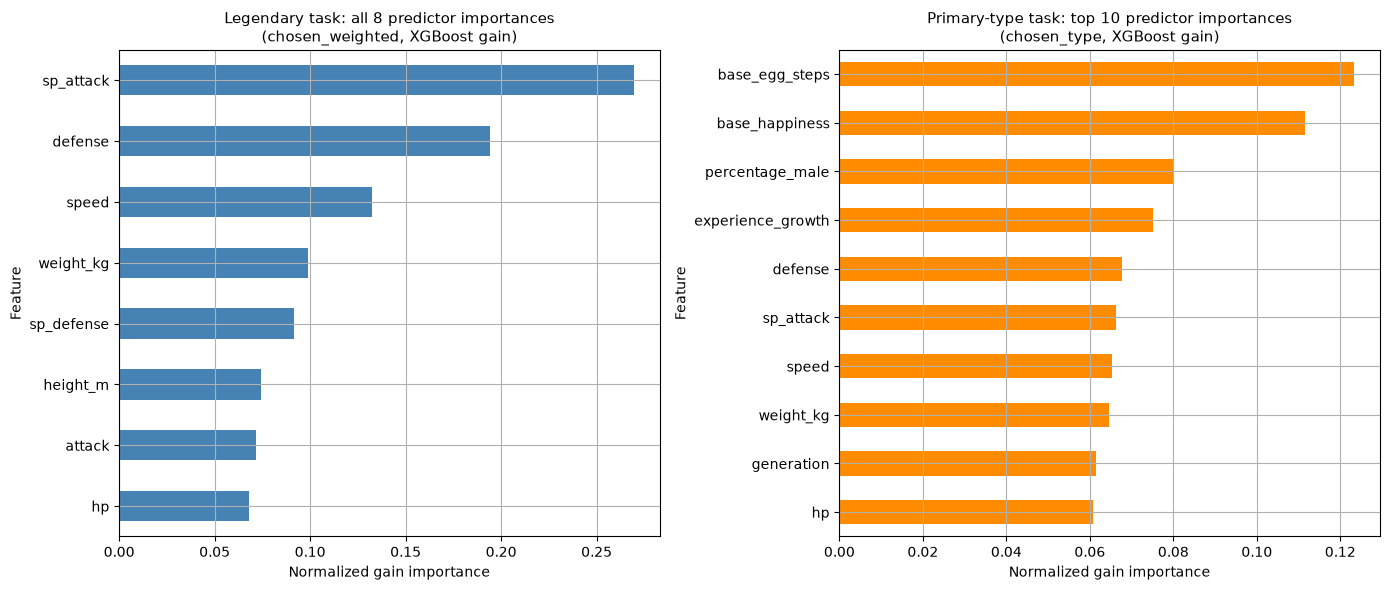

In [16]:
legendary_importances = pd.Series(
    chosen_weighted.feature_importances_,
    index=X_train_l.columns,
    name="importance (gain)",
).sort_values(ascending=False)

type_importances = pd.Series(
    chosen_type.feature_importances_,
    index=X_train_t.columns,
    name="importance (gain)",
).sort_values(ascending=False)

print("Top 3 legendary features:", legendary_importances.head(3).index.tolist())
print("Top 3 type features:", type_importances.head(3).index.tolist())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Legendary panel (all 8 predictors)
ax = axes[0]
legendary_importances.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Legendary task: all 8 predictor importances\n(chosen_weighted, XGBoost gain)", fontsize=11)
ax.set_xlabel("Normalized gain importance")
ax.set_ylabel("Feature")

# Type panel (top 10 predictors)
ax = axes[1]
type_importances.head(10).sort_values().plot.barh(ax=ax, color="darkorange")
ax.set_title("Primary-type task: top 10 predictor importances\n(chosen_type, XGBoost gain)", fontsize=11)
ax.set_xlabel("Normalized gain importance")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

**Part 6 — feature interpretation**

What do the leading features suggest about the two tasks? Explain one
limitation of using these global rankings to explain predictions.

For legendary status, `sp_attack`, `defense`, and `speed` lead by gain. This makes intuitive sense — legendary Pokémon tend to have exceptional battle stats, and special attack in particular is a strong differentiator. For primary type, the leading features are `base_egg_steps`, `base_happiness`, and `percentage_male`, which are game-design parameters rather than battle stats. This suggests the type classification relies more on biological and reproductive characteristics that game designers assigned consistently within type groups, rather than raw battle performance. The main limitation of global importance rankings is that they describe average contributions across all predictions in all trees, not contributions for any individual prediction. A feature can be globally unimportant but highly influential for a specific subset of Pokémon, or it can appear important because it proxies for a correlated feature — moving it wouldn't necessarily change predictions because another correlated feature would compensate.


## Part 7: Record choices and evaluate the test sets

### 7(a). Record the final models

Within your chosen library, compare `chosen_plain` and `chosen_weighted` by
validation AP. Treat values within `METRIC_TOLERANCE` of the maximum as tied
and prefer the unweighted fit when tied. Keep the winner as
`selected_legendary_model`. The other initial library and the diagnostic fits
are excluded.

Keep `chosen_type` as the type model. Before test predictions, record each
model's name, validation score (AP or macro-F1), and selected number of rounds
in a table. Keep both fits without refitting, and use the fixed 0.5 cutoff
for legendary classification. The table is the response for this step.


In [17]:
ap_plain = binary_metrics(y_val_l, chosen_plain_probs)["average_precision"]
ap_weighted = binary_metrics(y_val_l, weighted_probs)["average_precision"]

if ap_weighted - ap_plain > METRIC_TOLERANCE:
    selected_legendary_model = chosen_weighted
    selected_model_name = "chosen_weighted"
    selected_ap = ap_weighted
    selected_rounds = weighted_rounds
else:
    selected_legendary_model = chosen_plain
    selected_model_name = "chosen_plain"
    selected_ap = ap_plain
    selected_rounds = xgb_rounds

model_record = pd.DataFrame({
    "model": [selected_model_name, "chosen_type"],
    "task": ["legendary (binary)", "primary type (multiclass)"],
    "library": [CHOSEN_LIBRARY, CHOSEN_LIBRARY],
    "validation_score": [round(selected_ap, 6), round(type_booster_metrics["macro_f1"], 6)],
    "metric": ["average_precision", "macro_f1"],
    "selected_rounds": [selected_rounds, type_rounds],
})
display(model_record.set_index("model").rename_axis("recorded model"))

,task,library,validation_score,metric,selected_rounds
recorded model,,,,,
chosen_weighted,legendary (binary),XGBoost,0.910712,average_precision,318
chosen_type,primary type (multiclass),XGBoost,0.270195,macro_f1,93


### 7(b). Evaluate once

Evaluate `selected_legendary_model` and `baseline_l` on `X_test_l`, `y_test_l`.
Report `binary_metrics` at 0.5, including detections, misses, and false alarms,
and draw the booster's labeled confusion matrix. Evaluate `chosen_type` and
`baseline_t` on `X_test_t`, `y_test_t` using accuracy and macro-F1.

Report the number of legendary test positives and the smallest type-test
class support, naming every type tied at that support. Keep the recorded
choices after seeing these results.


,accuracy,average_precision,precision,recall,f1,log_loss,legendary_found,false_alarms,missed_legendary
"model (test, legendary)",,,,,,,,,
baseline_l,0.94375,0.504150,0.727273,0.571429,0.640000,0.225323,8.0,3.0,6.0
chosen_weighted,0.95000,0.810167,0.714286,0.714286,0.714286,0.139136,10.0,4.0,4.0


legendary_test_positives      14
legendary_found_by_booster    10
Name: legendary test summary, dtype: int64

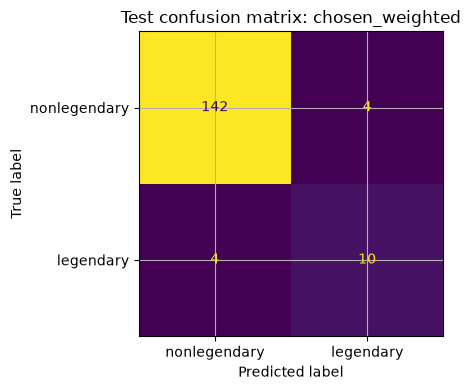

,accuracy,macro_f1
"model (test, type)",,
baseline_t,0.20000,0.112446
chosen_type,0.25625,0.236165


smallest_type_test_support            4
types_at_min_support          ['fairy']
Name: type test support summary, dtype: object

In [18]:
# Legendary test evaluation
test_probs = selected_legendary_model.predict_proba(X_test_l)[:, 1]
test_legendary_metrics = binary_metrics(y_test_l, test_probs)
baseline_test_metrics = binary_metrics(y_test_l, baseline_l.predict_proba(X_test_l)[:, 1])

display(
    pd.DataFrame({
        "baseline_l": baseline_test_metrics,
        selected_model_name: test_legendary_metrics,
    }).T.rename_axis("model (test, legendary)")
)

n_legendary_test_positives = int((y_test_l == 1).sum())
display(pd.Series({
    "legendary_test_positives": n_legendary_test_positives,
    "legendary_found_by_booster": int(test_legendary_metrics["legendary_found"]),
}, name="legendary test summary"))

# Confusion matrix for the booster
test_preds_binary = (test_probs >= 0.5).astype(int)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test_l, test_preds_binary),
    display_labels=["nonlegendary", "legendary"],
).plot(ax=ax, colorbar=False)
ax.set_title(f"Test confusion matrix: {selected_model_name}")
plt.tight_layout()
plt.show()

# Type test evaluation
type_test_preds = np.asarray(chosen_type.predict(X_test_t)).ravel()
baseline_test_type_preds = baseline_t.predict(X_test_t)

type_test_metrics = pd.Series({
    "accuracy": accuracy_score(y_test_t, type_test_preds),
    "macro_f1": f1_score(
        y_test_t, type_test_preds, average="macro",
        labels=np.arange(len(TYPE_NAMES_T)), zero_division=0,
    ),
})
baseline_type_test_metrics = pd.Series({
    "accuracy": accuracy_score(y_test_t, baseline_test_type_preds),
    "macro_f1": f1_score(
        y_test_t, baseline_test_type_preds, average="macro",
        labels=np.arange(len(TYPE_NAMES_T)), zero_division=0,
    ),
})
display(
    pd.DataFrame({
        "baseline_t": baseline_type_test_metrics,
        "chosen_type": type_test_metrics,
    }).T.rename_axis("model (test, type)")
)

# Type test supports
type_test_support_series = pd.Series(
    type_encoder.inverse_transform(y_test_t.to_numpy())
).value_counts().rename_axis("type").rename("test_support")
min_support = int(type_test_support_series.min())
min_support_types = type_test_support_series[type_test_support_series == min_support].index.tolist()
display(pd.Series({
    "smallest_type_test_support": min_support,
    "types_at_min_support": str(min_support_types),
}, name="type test support summary"))

**Part 7 — final reflection**

Give three short evidence-based bullets:

1. Compare each booster with its baseline and identify the harder task.
2. Explain one result from weighting or boosting trajectories.
3. State a limitation using the test class supports and the recorded-choice protocol.

- The legendary booster (`chosen_weighted`) finds 10 of 14 test legendaries vs. the baseline's 8, with AP of 0.810 vs. 0.504 — a substantial improvement. The type booster reaches 25.6% accuracy and macro-F1 of 0.236 vs. the baseline's 20.0% and 0.112, also a meaningful gain. Primary-type classification is the harder task: even the booster barely exceeds chance for many classes, while the legendary model clearly learns a separable boundary from battle stats.
- Class weighting improved recall on the validation set from 11/14 (chosen_plain) to 13/14 (chosen_weighted) while keeping false alarms at 5. The weighted model was therefore selected by validation AP (0.911 vs. 0.891). On the test set it found 10 of 14 legendaries with 4 false alarms. The trajectory plots showed that an overfitting rate (0.30) hits a lower validation loss early but then degrades, confirming why early stopping at round 40 would have been ideal for that rate.
- Fairy has only 4 test examples — the smallest class support — and near-zero F1 in both validation and test. With so few observations per class, any per-class metric is highly variable and unreliable. The recorded-choice protocol guards against inflated metrics: library selection and model choice were locked before testing, so test results couldn't retroactively favor a better-fitting alternative. The small supports reveal that some type distinctions simply can't be learned reliably at this dataset size.


## Submission check

- All required TODOs have been replaced with executable code, and the nine required
  written responses are complete.
- Tables identify validation versus test results; figures have readable titles,
  axes, legends, type names, and class labels as appropriate.
- Class weights, early stopping, and model selection use
  the specified partitions. Test results do not determine your choices.
- The supplied row filters are applied, and the source CSV, helper, and
  environment files remain unchanged.
- Restart the kernel and run the completed notebook from top to bottom. Commit
  `lab-08.ipynb`. Keep `.venv` and model files
  out of the submission.

## References

- Rounak Banik, [The Complete Pokémon Dataset](https://www.kaggle.com/datasets/rounakbanik/pokemon).
- [XGBoost categorical inputs](https://xgboost.readthedocs.io/en/release_3.1.0/tutorials/categorical.html),
  [scikit-learn interface and early stopping](https://xgboost.readthedocs.io/en/release_3.1.0/python/sklearn_estimator.html),
  and [boosted-tree objective](https://xgboost.readthedocs.io/en/release_3.1.0/tutorials/model.html).
- CatBoost [categorical features](https://catboost.ai/docs/en/features/categorical-features),
  [class weights and parameters](https://catboost.ai/docs/en/references/training-parameters/common),
  [staged probabilities](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_staged_predict_proba),
  and [built-in importance](https://catboost.ai/docs/en/concepts/fstr).
- Scikit-learn [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
